# Environment Setup and Imports

In [1]:
import os
import sys
from pathlib import Path

import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import cv2

from PIL import Image
from tqdm.auto import tqdm

import matplotlib.pyplot as plt

# Configure project paths

In [2]:
# Project root directory
PROJECT_ROOT = Path.cwd().parent

# Dataset directory
DATA_DIR = PROJECT_ROOT / "data"

# Model directory
MODEL_DIR = PROJECT_ROOT / "models" / "anti_spoofing"

# Results directory
RESULTS_DIR = PROJECT_ROOT / "results" / "anti_spoofing"

# Create required directories
MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Model directory:", MODEL_DIR)
print("Results directory:", RESULTS_DIR)

Project root: Y:\Python\AI ML\Month 2\week 8-NLP\47 — APPLE FACE ID  (FACIAL RECOGNITION PROJECTS)
Model directory: Y:\Python\AI ML\Month 2\week 8-NLP\47 — APPLE FACE ID  (FACIAL RECOGNITION PROJECTS)\models\anti_spoofing
Results directory: Y:\Python\AI ML\Month 2\week 8-NLP\47 — APPLE FACE ID  (FACIAL RECOGNITION PROJECTS)\results\anti_spoofing


In [3]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Device: cuda
GPU: NVIDIA GeForce GTX 1650


# Obtain MiniFASNetV2 Pretrained

In [4]:
import subprocess

THIRD_PARTY_DIR = PROJECT_ROOT / "third_party"
MINIFASNET_DIR = THIRD_PARTY_DIR / "face-anti-spoofing"

THIRD_PARTY_DIR.mkdir(exist_ok=True)

if not MINIFASNET_DIR.exists():

    subprocess.run(
        [
            "git",
            "clone",
            "https://github.com/yakhyo/face-anti-spoofing.git",
            str(MINIFASNET_DIR)
        ],
        check=True
    )

print("MiniFASNet repository:", MINIFASNET_DIR)

MiniFASNet repository: Y:\Python\AI ML\Month 2\week 8-NLP\47 — APPLE FACE ID  (FACIAL RECOGNITION PROJECTS)\third_party\face-anti-spoofing


In [5]:
import urllib.request

WEIGHTS_PATH = MODEL_DIR / "MiniFASNetV2.pth"

WEIGHTS_URL = (
    "https://github.com/yakhyo/face-anti-spoofing/"
    "releases/download/weights/MiniFASNetV2.pth"
)

if not WEIGHTS_PATH.exists():

    urllib.request.urlretrieve(
        WEIGHTS_URL,
        WEIGHTS_PATH
    )

print("Pretrained weights:", WEIGHTS_PATH)
print("File size:", round(WEIGHTS_PATH.stat().st_size / (1024 ** 2), 2), "MB")

Pretrained weights: Y:\Python\AI ML\Month 2\week 8-NLP\47 — APPLE FACE ID  (FACIAL RECOGNITION PROJECTS)\models\anti_spoofing\MiniFASNetV2.pth
File size: 1.8 MB


In [6]:
print("Architecture file exists:",
      (MINIFASNET_DIR / "models" / "fastnet.py").exists())

print("Pretrained weights exist:",
      WEIGHTS_PATH.exists())

print("Weights size:",
      WEIGHTS_PATH.stat().st_size if WEIGHTS_PATH.exists() else "Missing",
      "bytes")

Architecture file exists: True
Pretrained weights exist: True
Weights size: 1883219 bytes


# Load MiniFASNetV2

In [7]:
# Add the downloaded repository to Python's import path
sys.path.insert(0, str(MINIFASNET_DIR))

from models.fastnet import MiniFASNetV2

# Initialize architecture
antispoof_model = MiniFASNetV2().to(device)

# Load pretrained weights
state_dict = torch.load(
    WEIGHTS_PATH,
    map_location=device,
    weights_only=True
)

# Apply weights
antispoof_model.load_state_dict(state_dict)

# Evaluation mode
antispoof_model.eval()

print("Device:", device)

Device: cuda


In [8]:
# Testing 

# Create a dummy RGB image
dummy_input = torch.randn(
    1, 3, 80, 80
).to(device)

# Run inference
with torch.no_grad():
    output = antispoof_model(dummy_input)

    probabilities = torch.softmax(output, dim=1)

print("Input shape:", dummy_input.shape)
print("Output shape:", output.shape)
print("Probabilities:", probabilities.cpu().numpy())

print(
    "Probability sum:",
    probabilities.sum(dim=1).item()
)

Input shape: torch.Size([1, 3, 80, 80])
Output shape: torch.Size([1, 3])
Probabilities: [[0.00690996 0.01332101 0.97976905]]
Probability sum: 1.0


# Preprocessing analysis

In [9]:
def crop_face(image, bbox, scale=2.7):

    src_h, src_w = image.shape[:2]

    x, y, box_w, box_h = bbox

    scale = min(
        (src_h - 1) / box_h,
        (src_w - 1) / box_w,
        scale
    )

    new_w = box_w * scale
    new_h = box_h * scale

    center_x = x + box_w / 2
    center_y = y + box_h / 2

    x1 = max(0, int(center_x - new_w / 2))
    y1 = max(0, int(center_y - new_h / 2))

    x2 = min(src_w - 1, int(center_x + new_w / 2))
    y2 = min(src_h - 1, int(center_y + new_h / 2))

    cropped = image[y1:y2 + 1, x1:x2 + 1]

    return cv2.resize(cropped, (80, 80))

In [10]:
def preprocess_face(face):

    face = face.astype(np.float32)

    face = np.transpose(face, (2, 0, 1))

    face = np.expand_dims(face, axis=0)

    face_tensor = torch.from_numpy(face)

    return face_tensor.to(device)

In [11]:
dummy_image = np.zeros(
    (480, 640, 3),
    dtype=np.uint8
)

dummy_bbox = [200, 100, 150, 180]

cropped_face = crop_face(
    dummy_image,
    dummy_bbox
)

face_tensor = preprocess_face(cropped_face)

print("Original image:", dummy_image.shape)
print("Cropped face:", cropped_face.shape)
print("Tensor shape:", face_tensor.shape)
print("Tensor dtype:", face_tensor.dtype)
print("Tensor device:", face_tensor.device)
print("Minimum value:", face_tensor.min().item())
print("Maximum value:", face_tensor.max().item())

Original image: (480, 640, 3)
Cropped face: (80, 80, 3)
Tensor shape: torch.Size([1, 3, 80, 80])
Tensor dtype: torch.float32
Tensor device: cuda:0
Minimum value: 0.0
Maximum value: 0.0


# Real image inference

In [12]:
from uniface import RetinaFace
from pathlib import Path
import numpy as np
import cv2

face_detector = RetinaFace()

TEST_IMAGE_PATH = Path(
    DATA_DIR / "antispoofing" / "test_real.jpg"
)

if not TEST_IMAGE_PATH.is_file():
    raise FileNotFoundError(TEST_IMAGE_PATH)

# Unicode-safe image loading
image_data = np.fromfile(
    str(TEST_IMAGE_PATH),
    dtype=np.uint8
)

image = cv2.imdecode(
    image_data,
    cv2.IMREAD_COLOR
)

if image is None:
    raise ValueError("Image decoding failed.")

print("Image shape:", image.shape)
print("Image dtype:", image.dtype)
print("Image size:", TEST_IMAGE_PATH.stat().st_size, "bytes")

Image shape: (1308, 736, 3)
Image dtype: uint8
Image size: 98280 bytes


In [13]:
faces = face_detector.detect(image)

print("Number of faces detected:", len(faces))

for i, face in enumerate(faces):
    print(f"\nFace {i + 1}")
    print("Bounding box:", face.bbox)
    print("Confidence:", face.confidence)

Number of faces detected: 1

Face 1
Bounding box: [260.52502 452.4914  437.19382 692.6957 ]
Confidence: 0.9998568296432495


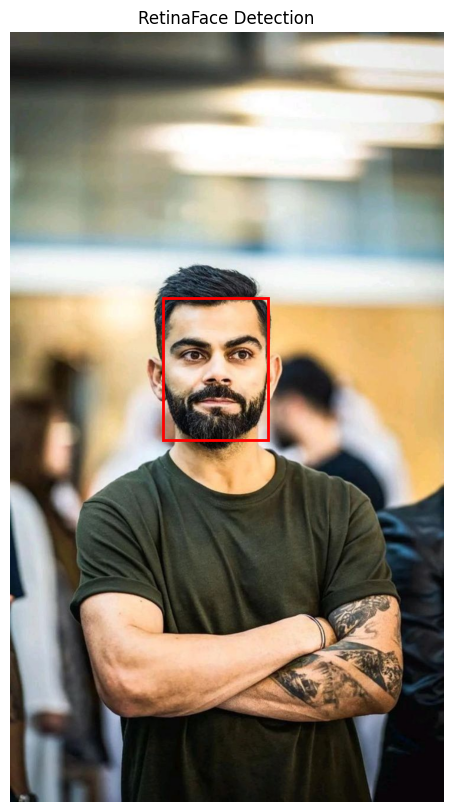

In [14]:
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 10))
plt.imshow(image_rgb)

for face in faces:
    x1, y1, x2, y2 = map(int, face.bbox)

    plt.gca().add_patch(
        plt.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            edgecolor="red",
            linewidth=2
        )
    )

plt.axis("off")
plt.title("RetinaFace Detection")
plt.show()

# MiniFASNetV2 real-image inference

In [15]:
face = faces[0]

# Convert XYXY bounding box to XYWH
x1, y1, x2, y2 = face.bbox

bbox_xywh = [
    int(x1),
    int(y1),
    int(x2 - x1),
    int(y2 - y1)
]

# Crop and preprocess
cropped_face = crop_face(
    image,
    bbox_xywh,
    scale=2.7
)

face_tensor = preprocess_face(cropped_face)

print("Bounding box:", bbox_xywh)
print("Cropped image:", cropped_face.shape)
print("Input tensor:", face_tensor.shape)

Bounding box: [260, 452, 176, 240]
Cropped image: (80, 80, 3)
Input tensor: torch.Size([1, 3, 80, 80])


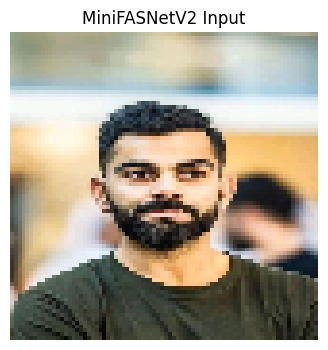

In [16]:
plt.figure(figsize=(4, 4))

plt.imshow(cv2.cvtColor(cropped_face, cv2.COLOR_BGR2RGB))

plt.title("MiniFASNetV2 Input")
plt.axis("off")
plt.show()

In [17]:
with torch.no_grad():

    logits = antispoof_model(face_tensor)

    probabilities = torch.softmax(logits, dim=1)

probabilities = probabilities.cpu().numpy()[0]

predicted_class = int(np.argmax(probabilities))

label = "Real" if predicted_class == 1 else "Fake"

print("Predicted class:", predicted_class)
print("Prediction:", label)

print("\nClass probabilities:")

for i, probability in enumerate(probabilities):
    print(f"Class {i}: {probability:.6f}")

print(f"\nConfidence: {probabilities[predicted_class] * 100:.2f}%")

Predicted class: 2
Prediction: Fake

Class probabilities:
Class 0: 0.032880
Class 1: 0.194013
Class 2: 0.773107

Confidence: 77.31%


In [18]:
from pathlib import Path

DATASET_DIR = (
    PROJECT_ROOT / "data" / "antispoofing" / "raw"
)

CLIENT_DIR = DATASET_DIR / "ClientRaw" / "0001"
IMPOSTER_DIR = DATASET_DIR / "ImposterRaw" / "0001"

client_images = [
    p for p in CLIENT_DIR.iterdir()
    if p.is_file()
]

imposter_images = [
    p for p in IMPOSTER_DIR.iterdir()
    if p.is_file()
]

print("ClientRaw 0001:", len(client_images))
print("ImposterRaw 0001:", len(imposter_images))

print("\nClient samples:")
print([p.name for p in client_images[:5]])

print("\nImposter samples:")
print([p.name for p in imposter_images[:5]])

ClientRaw 0001: 250
ImposterRaw 0001: 615

Client samples:
['0001_00_00_01_0.jpg', '0001_00_00_01_101.jpg', '0001_00_00_01_105.jpg', '0001_00_00_01_109.jpg', '0001_00_00_01_112.jpg']

Imposter samples:
['0001_00_00_01_0.jpg', '0001_00_00_01_102.jpg', '0001_00_00_01_107.jpg', '0001_00_00_01_111.jpg', '0001_00_00_01_116.jpg']


In [19]:
def evaluate_folder(image_paths, ground_truth):

    results = []

    for image_path in tqdm(
        image_paths,
        desc=f"Evaluating {ground_truth}",
        unit="image"
    ):

        image_data = np.fromfile(str(image_path), dtype=np.uint8)
        image = cv2.imdecode(image_data, cv2.IMREAD_COLOR)

        if image is None:
            continue

        faces = face_detector.detect(image)

        if not faces:
            results.append({
                "image": str(image_path),
                "subject": image_path.parent.name,
                "ground_truth": ground_truth,
                "status": "No face detected"
            })
            continue

        face = max(faces, key=lambda item: item.confidence)

        bbox = face.bbox

        cropped_face = crop_face(image, bbox)
        face_tensor = preprocess_face(cropped_face)

        with torch.inference_mode():

            logits = antispoof_model(face_tensor)

            probabilities = torch.softmax(
                logits, dim=1
            )[0].cpu().numpy()

        predicted_class = int(np.argmax(probabilities))

        predicted_label = (
            "Real" if predicted_class == 1 else "Fake"
        )

        results.append({
            "image": str(image_path),
            "subject": image_path.parent.name,
            "ground_truth": ground_truth,
            "predicted": predicted_label,
            "class_0_fake": float(probabilities[0]),
            "class_1_real": float(probabilities[1]),
            "class_2_fake": float(probabilities[2]),
            "combined_fake": float(probabilities[0] + probabilities[2]),
            "confidence": float(probabilities[predicted_class]),
            "correct": predicted_label == ground_truth,
            "status": "Success"
        })

    return results

In [20]:
# testing on entire dataset 

from pathlib import Path

DATASET_DIR = PROJECT_ROOT / "data" / "antispoofing" / "raw"

CLIENT_ROOT = DATASET_DIR / "ClientRaw"
IMPOSTER_ROOT = DATASET_DIR / "ImposterRaw"

client_images = sorted(
    CLIENT_ROOT.rglob("*.jpg")
)

imposter_images = sorted(
    IMPOSTER_ROOT.rglob("*.jpg")
)

print("CLIENT DATASET")
print("Total images:", len(client_images))

print("\nIMPOSTER DATASET")
print("Total images:", len(imposter_images))

print("\nTOTAL IMAGES:", len(client_images) + len(imposter_images))

CLIENT DATASET
Total images: 5105

IMPOSTER DATASET
Total images: 7509

TOTAL IMAGES: 12614


In [21]:
all_results = []

# Genuine images
real_results = evaluate_folder(client_images, "Real")

# Spoof images
fake_results = evaluate_folder(imposter_images, "Fake")

# Combine results
all_results = real_results + fake_results

full_results_df = pd.DataFrame(all_results)

print("\nEvaluation completed!")
print("Total records:", len(full_results_df))

print("\nStatus distribution:")
print(full_results_df["status"].value_counts())

Evaluating Real:   0%|          | 0/5105 [00:00<?, ?image/s]

Evaluating Fake:   0%|          | 0/7509 [00:00<?, ?image/s]


Evaluation completed!
Total records: 12614

Status distribution:
status
Success    12614
Name: count, dtype: int64


In [22]:
full_results_df

,image,subject,ground_truth,predicted,class_0_fake,class_1_real,class_2_fake,combined_fake,confidence,correct,status
0,Y:\Python\AI ML\Month 2\week 8-NLP\47 — APPLE ...,0001,Real,Real,0.007543,9.818785e-01,1.057858e-02,0.018122,0.981878,True,Success
1,Y:\Python\AI ML\Month 2\week 8-NLP\47 — APPLE ...,0001,Real,Real,0.000599,9.990805e-01,3.200303e-04,0.000919,0.999081,True,Success
2,Y:\Python\AI ML\Month 2\week 8-NLP\47 — APPLE ...,0001,Real,Real,0.000895,9.988978e-01,2.076514e-04,0.001102,0.998898,True,Success
3,Y:\Python\AI ML\Month 2\week 8-NLP\47 — APPLE ...,0001,Real,Real,0.001453,9.973895e-01,1.157283e-03,0.002610,0.997389,True,Success
4,Y:\Python\AI ML\Month 2\week 8-NLP\47 — APPLE ...,0001,Real,Real,0.000924,9.985126e-01,5.630623e-04,0.001487,0.998513,True,Success
...,...,...,...,...,...,...,...,...,...,...,...
12609,Y:\Python\AI ML\Month 2\week 8-NLP\47 — APPLE ...,0016,Fake,Fake,1.000000,2.745727e-07,8.440252e-08,1.000000,1.000000,True,Success
12610,Y:\Python\AI ML\Month 2\week 8-NLP\47 — APPLE ...,0016,Fake,Fake,1.000000,6.638439e-09,3.737410e-09,1.000000,1.000000,True,Success
12611,Y:\Python\AI ML\Month 2\week 8-NLP\47 — APPLE ...,0016,Fake,Fake,0.999999,8.022254e-07,1.357688e-07,0.999999,0.999999,True,Success
12612,Y:\Python\AI ML\Month 2\week 8-NLP\47 — APPLE ...,0016,Fake,Fake,0.999996,1.969311e-06,1.697413e-06,0.999998,0.999996,True,Success


In [23]:
full_results_df['status'].value_counts()

status
Success    12614
Name: count, dtype: int64

In [24]:
full_results_df['correct'].value_counts()

correct
True     12065
False      549
Name: count, dtype: int64

In [25]:
true_positive = full_results_df[
    ((full_results_df['ground_truth'] == 'Real') & (full_results_df['predicted'] == 'Real'))]

true_negative = full_results_df[
    ((full_results_df['ground_truth'] == 'Fake') & (full_results_df['predicted'] == 'Fake'))]

false_positive = full_results_df[
    ((full_results_df['ground_truth'] == 'Fake') & (full_results_df['predicted'] == 'Real'))]

false_negative = full_results_df[
    ((full_results_df['ground_truth'] == 'Real') & (full_results_df['predicted'] == 'Fake'))]

In [26]:
print('True Positive: ',len(true_positive))
print('True Negative: ',len(true_negative))
print('False Positive: ',len(false_positive))
print('False Negative: ',len(false_negative))

True Positive:  4627
True Negative:  7438
False Positive:  71
False Negative:  478


In [27]:
tp = len(true_positive)
tn = len(true_negative)
fp = len(false_positive)
fn = len(false_negative)

total = tp + tn + fp + fn

accuracy = (tp + tn) / total

far = fp / (fp + tn)
frr = fn / (fn + tp)

tpr = tp / (tp + fn)
tnr = tn / (tn + fp)

precision = tp / (tp + fp)
balanced_accuracy = (tpr + tnr) / 2

metrics = {
    "total_images": total,
    "accuracy": accuracy,
    "precision": precision,
    "far": far,
    "frr": frr,
    "true_positive_rate": tpr,
    "true_negative_rate": tnr,
    "balanced_accuracy": balanced_accuracy
}

for name, value in metrics.items():
    print(f"{name}: {value:.6f}")

total_images: 12614.000000
accuracy: 0.956477
precision: 0.984887
far: 0.009455
frr: 0.093634
true_positive_rate: 0.906366
true_negative_rate: 0.990545
balanced_accuracy: 0.948455


In [28]:
full_results_df[['class_0_fake','class_1_real','class_2_fake']].mean()

class_0_fake    0.564772
class_1_real    0.358457
class_2_fake    0.076771
dtype: float64

In [30]:
import json
from datetime import datetime

# Create results directory
results_dir = Path(PROJECT_ROOT/"results/antispoofing")
results_dir.mkdir(parents=True, exist_ok=True)

# Final evaluation metrics
metrics = {
    "total_images": 12614,
    "accuracy": 0.956477,
    "precision": 0.984887,
    "far": 0.009455,
    "frr": 0.093634,
    "true_positive_rate": 0.906366,
    "true_negative_rate": 0.990545,
    "balanced_accuracy": 0.948455
}

# Confusion matrix
confusion_matrix_data = {
    "true_positive": 4627,
    "true_negative": 7438,
    "false_positive": 71,
    "false_negative": 478
}

# Model configuration
model_config = {
    "model": "MiniFASNetV2",
    "pretrained": True,
    "input_size": [80, 80],
    "crop_scale": 2.7,
    "face_detector": "RetinaFace",
    "classification": {
        "class_0": "Fake",
        "class_1": "Real",
        "class_2": "Fake"
    },
    "prediction_rule": "Real if predicted_class == 1, otherwise Fake",
    "dataset": "NUAA",
    "total_images": 12614
}

# Combine everything
evaluation_report = {
    "evaluation_date": datetime.now().strftime("%Y-%m-%d"),
    "metrics": metrics,
    "confusion_matrix": confusion_matrix_data,
    "model_configuration": model_config
}

# Save JSON report
with open(results_dir / "nuaa_evaluation_report.json", "w") as file:
    json.dump(evaluation_report, file, indent=4)

# Save metrics CSV
pd.DataFrame([metrics]).to_csv(
    results_dir / "nuaa_metrics.csv",
    index=False
)

# Save per-image predictions
full_results_df.to_csv(
    results_dir / "nuaa_image_predictions.csv",
    index=False
)

print("Anti-spoofing evaluation saved successfully!")

for file in results_dir.iterdir():
    print(f"Saved: {file}")

Anti-spoofing evaluation saved successfully!
Saved: Y:\Python\AI ML\Month 2\week 8-NLP\47 — APPLE FACE ID  (FACIAL RECOGNITION PROJECTS)\results\antispoofing\.ipynb_checkpoints
Saved: Y:\Python\AI ML\Month 2\week 8-NLP\47 — APPLE FACE ID  (FACIAL RECOGNITION PROJECTS)\results\antispoofing\nuaa_evaluation_report.json
Saved: Y:\Python\AI ML\Month 2\week 8-NLP\47 — APPLE FACE ID  (FACIAL RECOGNITION PROJECTS)\results\antispoofing\nuaa_image_predictions.csv
Saved: Y:\Python\AI ML\Month 2\week 8-NLP\47 — APPLE FACE ID  (FACIAL RECOGNITION PROJECTS)\results\antispoofing\nuaa_metrics.csv
